# Lab 2 — Segmentation de la clientèle bancaire

**Formation Machine Learning pour le secteur bancaire** · Lab Clustering (corrigé commenté)

| | |
|---|---|
| **Problème métier** | La banque veut regrouper ses clients en **segments homogènes** pour adapter ses offres, sa communication et son pilotage du risque. |
| **Type de problème** | Apprentissage **non supervisé** — **clustering** (pas de variable cible) |
| **Données** | *Bank Marketing* (UCI) — 45 211 clients d'une banque portugaise ; profil socio-démographique et bancaire |
| **Modèles** | K-Means · K-Prototypes · Classification Ascendante Hiérarchique (CAH) |

### Déroulé du lab
1. Cadrage métier
2. Analyse exploratoire (EDA)
3. Preprocessing (transformation, encodage, échantillonnage)
4. Feature engineering
5. K-Means
6. K-Prototypes (données mixtes)
7. Classification ascendante hiérarchique
8. Comparaison des approches
9. Profilage métier & personas
10. Mise en production : affectation des nouveaux clients et suivi de la dérive

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from kmodes.kprototypes import KPrototypes
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
DATA_PATH = "data/bank_marketing.csv"

---
## 1. Cadrage métier

**Pourquoi segmenter ?**
- **Marketing** : proposer la bonne offre au bon client (*next best offer*), personnaliser la communication.
- **Risque** : repérer des populations fragiles (soldes négatifs, multi-endettement).
- **Pilotage** : suivre la rentabilité et l'évolution du portefeuille par segment.

**Différence avec le Lab 1 :** il n'y a **pas de bonne réponse** connue. L'algorithme propose des groupes ; c'est l'**expertise métier** qui juge s'ils sont **utiles** (interprétables, actionnables, stables, de taille suffisante).

**Variables retenues pour la segmentation** — le *profil client* uniquement :

| Variable | Type | Description |
|---|---|---|
| `age` | numérique | Âge |
| `balance` | numérique | Solde moyen annuel (€) |
| `job` | catégorielle | Profession (12 modalités) |
| `marital` | catégorielle | Statut marital |
| `education` | catégorielle | Niveau d'études |
| `default` | catégorielle | Incident de crédit (défaut) |
| `housing` | catégorielle | Crédit immobilier en cours |
| `loan` | catégorielle | Crédit personnel en cours |

Les variables de **campagne marketing** (`contact`, `duration`, `campaign`…) décrivent un *appel*, pas un *client* : on les exclut. La variable `y` (souscription à un **dépôt à terme**) n'est **pas** utilisée pour construire les segments ; elle servira à les **évaluer a posteriori** (quel segment est le plus appétent ?).

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Dimensions : {raw.shape[0]} clients × {raw.shape[1]} colonnes")
NUM_COLS = ["age", "balance"]
CAT_COLS = ["job", "marital", "education", "default", "housing", "loan"]
df = raw[NUM_COLS + CAT_COLS + ["y"]].copy()
df.head()

Dimensions : 45211 clients × 17 colonnes


,age,balance,job,marital,education,default,housing,loan,y
0,58,2143,management,married,tertiary,no,yes,no,no
1,44,29,technician,single,secondary,no,yes,no,no
2,33,2,entrepreneur,married,secondary,no,yes,yes,no
3,47,1506,blue-collar,married,unknown,no,yes,no,no
4,33,1,unknown,single,unknown,no,no,no,no


---
## 2. Analyse exploratoire (EDA)
### 2.1 Variables numériques

In [3]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
df[NUM_COLS].describe().T

Valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
age,45211.000,40.936,10.619,18.000,33.000,39.000,48.000,95.000
balance,45211.000,1362.272,3044.766,-8019.000,72.000,448.000,1428.000,102127.000


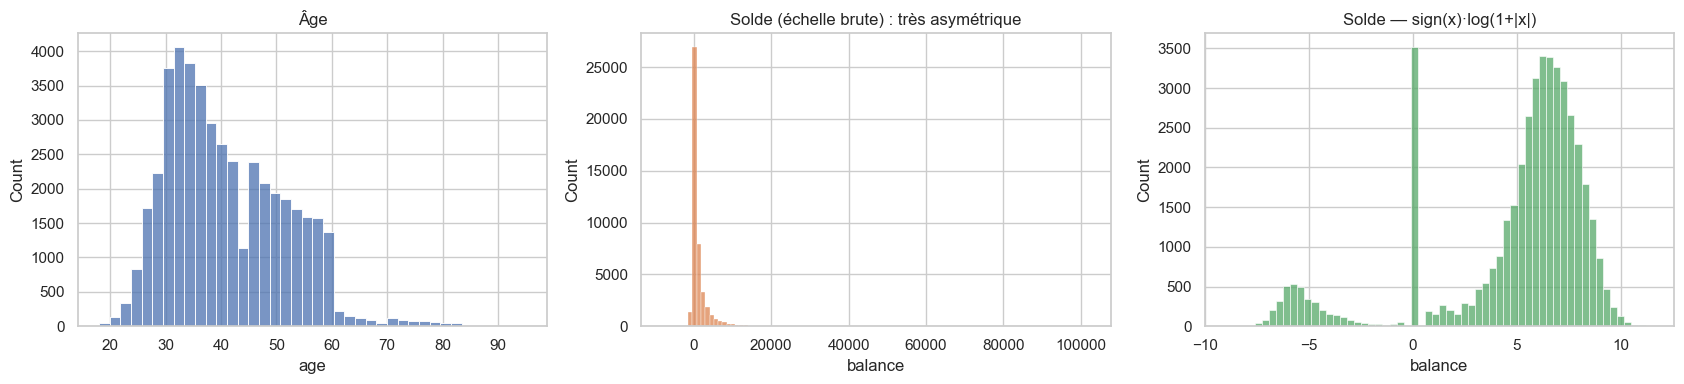

Soldes négatifs : 8.3% des clients  |  skewness du solde : 8.4  |  max : 102,127 €


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["age"], bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Âge")
sns.histplot(df["balance"], bins=100, ax=axes[1], color="#DD8452")
axes[1].set_title("Solde (échelle brute) : très asymétrique")
sns.histplot(np.sign(df["balance"]) * np.log1p(np.abs(df["balance"])), bins=60, ax=axes[2], color="#55A868")
axes[2].set_title("Solde — sign(x)·log(1+|x|)")
plt.tight_layout()
plt.show()
print(f"Soldes négatifs : {(df['balance'] < 0).mean():.1%} des clients  |  "
      f"skewness du solde : {df['balance'].skew():.1f}  |  max : {df['balance'].max():,.0f} €")

**Lecture :** le solde est **extrêmement asymétrique** (quelques clients à plus de 100 000 €) et comporte des **valeurs négatives** (découverts). Les algorithmes à base de distance (K-Means) seraient dominés par ces extrêmes : il faudra **transformer** cette variable (Yeo-Johnson, qui accepte les valeurs négatives, contrairement au log).

### 2.2 Variables catégorielles

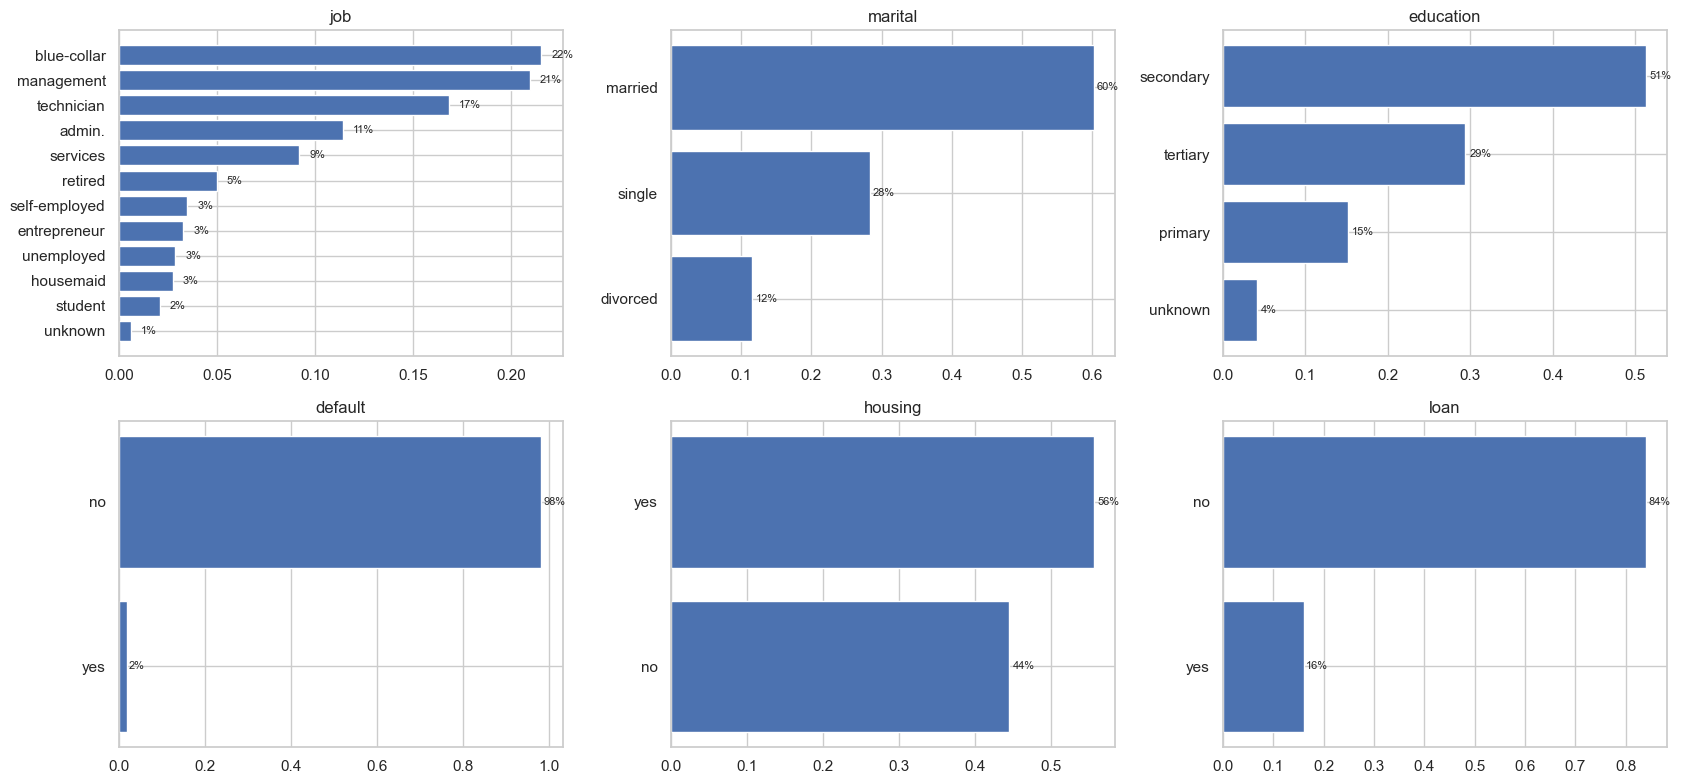

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, CAT_COLS):
    vc = df[col].value_counts(normalize=True)
    ax.barh(vc.index, vc.values, color="#4C72B0")
    ax.set_title(col)
    ax.invert_yaxis()
    for i, v in enumerate(vc.values):
        ax.text(v + 0.005, i, f"{v:.0%}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Lecture :**
- `job` a 12 modalités dont certaines **rares** (`unknown` 0,6 %, `student` 2 %) → regroupement utile.
- `default` est **très déséquilibrée** (98 % « no ») : elle pèsera peu dans les segments mais signale une population à risque.
- 56 % des clients ont un **crédit immobilier**, 16 % un **crédit personnel**.
- Modalités `unknown` (`education` 4 %) : on les garde comme modalité à part entière (l'absence d'information est une information).

### 2.3 Liens entre variables catégorielles : le V de Cramér

Le **V de Cramér** (0 = indépendance, 1 = lien parfait) est l'équivalent de la corrélation pour deux variables catégorielles.

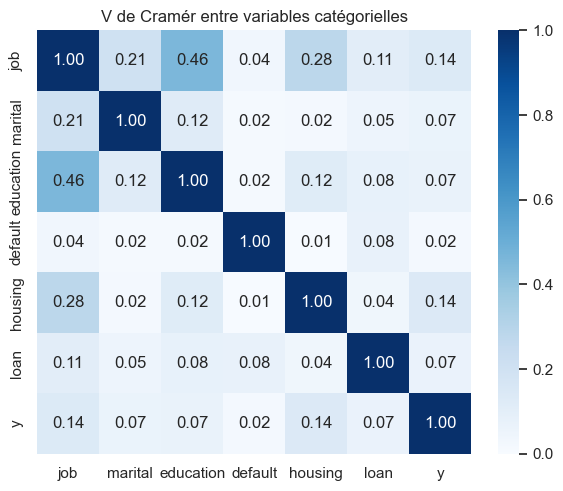

In [6]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cols = CAT_COLS + ["y"]
cv_matrix = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cols] for a in cols], index=cols, columns=cols)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cv_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("V de Cramér entre variables catégorielles")
plt.show()

**Lecture :** `job` et `education` sont les plus **liées** (V ≈ 0,46 : les cadres sont plus souvent diplômés du supérieur), puis `job`–`housing` (≈ 0,28) et `job`–`marital` (≈ 0,21, via l'âge : étudiants, retraités). Les autres liens sont faibles : chaque variable apporte une information **complémentaire** aux segments. Côté souscription (`y`), la profession et le crédit immobilier sont les plus informatifs.

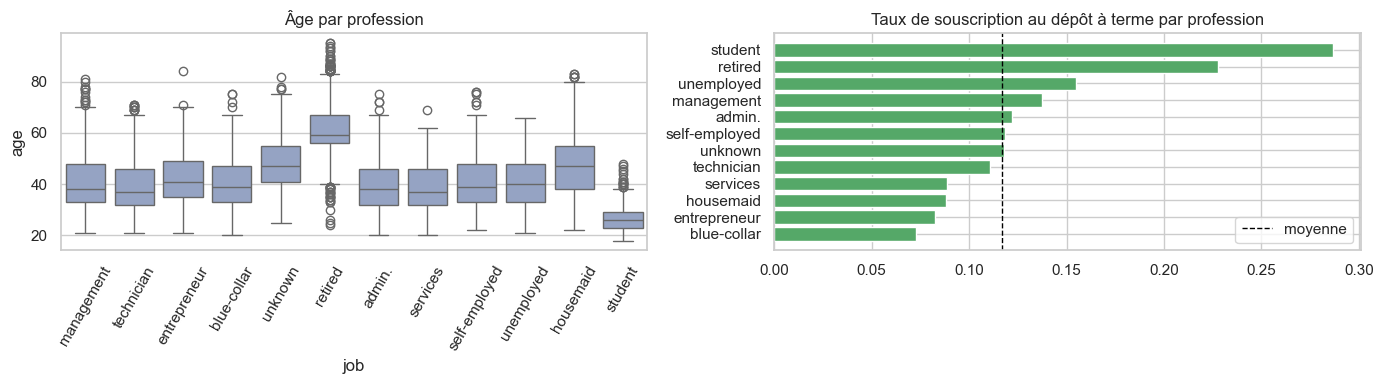

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="job", y="age", ax=axes[0], color="#8DA0CB")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Âge par profession")
rate = df.assign(sub=(df["y"] == "yes")).groupby("job")["sub"].mean().sort_values()
axes[1].barh(rate.index, rate.values, color="#55A868")
axes[1].axvline((df["y"] == "yes").mean(), color="black", ls="--", lw=1, label="moyenne")
axes[1].set_title("Taux de souscription au dépôt à terme par profession")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## 3 & 4. Feature engineering et preprocessing

### Feature engineering

| Nouvelle variable | Construction | Intérêt |
|---|---|---|
| `job_group` | 12 professions → 5 groupes socio-professionnels | Moins de modalités, segments plus lisibles |
| `nb_credits` | `housing` + `loan` (0, 1 ou 2) | Niveau d'endettement |
| `negative_balance` | solde < 0 | Indicateur de fragilité (pour le profilage) |
| `age_group` | tranches d'âge | Pour le profilage et les dashboards |

In [8]:
JOB_GROUPS = {
    "management": "Cadres & indépendants", "entrepreneur": "Cadres & indépendants",
    "self-employed": "Cadres & indépendants",
    "admin.": "Employés & techniciens", "technician": "Employés & techniciens", "services": "Employés & techniciens",
    "blue-collar": "Ouvriers & services", "housemaid": "Ouvriers & services",
    "retired": "Retraités",
    "student": "Étudiants & sans emploi", "unemployed": "Étudiants & sans emploi", "unknown": "Étudiants & sans emploi",
}

def add_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d["job_group"] = d["job"].map(JOB_GROUPS).fillna("Étudiants & sans emploi")
    d["nb_credits"] = (d["housing"] == "yes").astype(int) + (d["loan"] == "yes").astype(int)
    d["negative_balance"] = (d["balance"] < 0).astype(int)
    d["age_group"] = pd.cut(d["age"], [0, 30, 40, 50, 60, 120],
                            labels=["<30", "30-39", "40-49", "50-59", "60+"]).astype(str)
    return d

df = add_features(df)
df["job_group"].value_counts(normalize=True)

job_group
Employés & techniciens    0.374
Cadres & indépendants     0.277
Ouvriers & services       0.243
Étudiants & sans emploi   0.056
Retraités                 0.050
Name: proportion, dtype: float64

### Preprocessing

Variables utilisées par les algorithmes :
- **Numériques** : `age`, `balance` → **Yeo-Johnson** (réduit l'asymétrie, accepte les négatifs) puis **standardisation**. Sans standardisation, le solde (en milliers d'€) écraserait l'âge (en années) dans le calcul des distances.
- **Catégorielles** : `job_group`, `marital`, `education`, `default`, `housing`, `loan`
  - pour **K-Means / CAH Ward** : **one-hot encoding** (ces algorithmes ne connaissent que les distances euclidiennes) ;
  - pour **K-Prototypes** : utilisées **telles quelles** (distance de Hamming = nombre de modalités différentes).

In [9]:
SEG_NUM = ["age", "balance"]
SEG_CAT = ["job_group", "marital", "education", "default", "housing", "loan"]

num_pipe = Pipeline([("yeojohnson", PowerTransformer(method="yeo-johnson")), ("scaler", StandardScaler())])
encoder = ColumnTransformer([
    ("num", num_pipe, SEG_NUM),
    ("cat", OneHotEncoder(sparse_output=False), SEG_CAT),
])
X_onehot = encoder.fit_transform(df)
onehot_names = encoder.get_feature_names_out()
print(f"Matrice one-hot : {X_onehot.shape}")

num_scaled = encoder.named_transformers_["num"].transform(df[SEG_NUM])
print(f"Skewness du solde : brut {df['balance'].skew():.1f} → transformé {pd.Series(num_scaled[:, 1]).skew():.2f}")

Matrice one-hot : (45211, 20)
Skewness du solde : brut 8.4 → transformé 1.10


**Échantillonnage.** Certains calculs ne passent pas à l'échelle sur 45 000 clients :

| Calcul | Complexité | Choix |
|---|---|---|
| K-Means | linéaire, rapide | tous les clients |
| Silhouette | O(n²) | échantillon de 5 000 |
| K-Prototypes (entraînement) | plus lent (itératif, données mixtes) | échantillon de 10 000, puis **affectation** de tous les clients |
| CAH | O(n²) en mémoire | échantillon de 3 000 |

Un échantillon **aléatoire** de plusieurs milliers de clients est représentatif ; on peut vérifier que ses distributions sont proches de la population.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
idx_sil = rng.choice(len(df), 5000, replace=False)
idx_kp = rng.choice(len(df), 10000, replace=False)
idx_cah = rng.choice(len(df), 3000, replace=False)

pd.DataFrame({
    "Population": [df["age"].mean(), df["balance"].median(), (df["housing"] == "yes").mean()],
    "Échantillon K-Prototypes": [df["age"].iloc[idx_kp].mean(), df["balance"].iloc[idx_kp].median(),
                                 (df["housing"].iloc[idx_kp] == "yes").mean()],
    "Échantillon CAH": [df["age"].iloc[idx_cah].mean(), df["balance"].iloc[idx_cah].median(),
                        (df["housing"].iloc[idx_cah] == "yes").mean()],
}, index=["Âge moyen", "Solde médian", "% crédit immo"])

,Population,Échantillon K-Prototypes,Échantillon CAH
Âge moyen,40.936,41.108,40.991
Solde médian,448.000,445.000,472.500
% crédit immo,0.556,0.547,0.565


---
## 5. K-Means

**Principe :**
1. Choisir *k* centres au hasard (K-Means++ : bien répartis).
2. Affecter chaque client au centre **le plus proche**.
3. Recalculer chaque centre comme la **moyenne** de ses clients.
4. Répéter 2–3 jusqu'à stabilité.

K-Means minimise l'**inertie** (somme des distances au carré entre chaque client et son centre). Il faut **choisir k** à l'avance.

### 5.1 Choisir k : coude, silhouette, Davies-Bouldin, Calinski-Harabasz

| Métrique | Mesure | Meilleur |
|---|---|---|
| **Inertie** (méthode du coude) | compacité des groupes | « coude » de la courbe |
| **Silhouette** | cohésion interne vs séparation des autres groupes (−1 à 1) | ↑ élevé |
| **Davies-Bouldin** | ressemblance moyenne entre chaque groupe et son plus proche voisin | ↓ faible |
| **Calinski-Harabasz** | variance inter-groupes / intra-groupes | ↑ élevé |

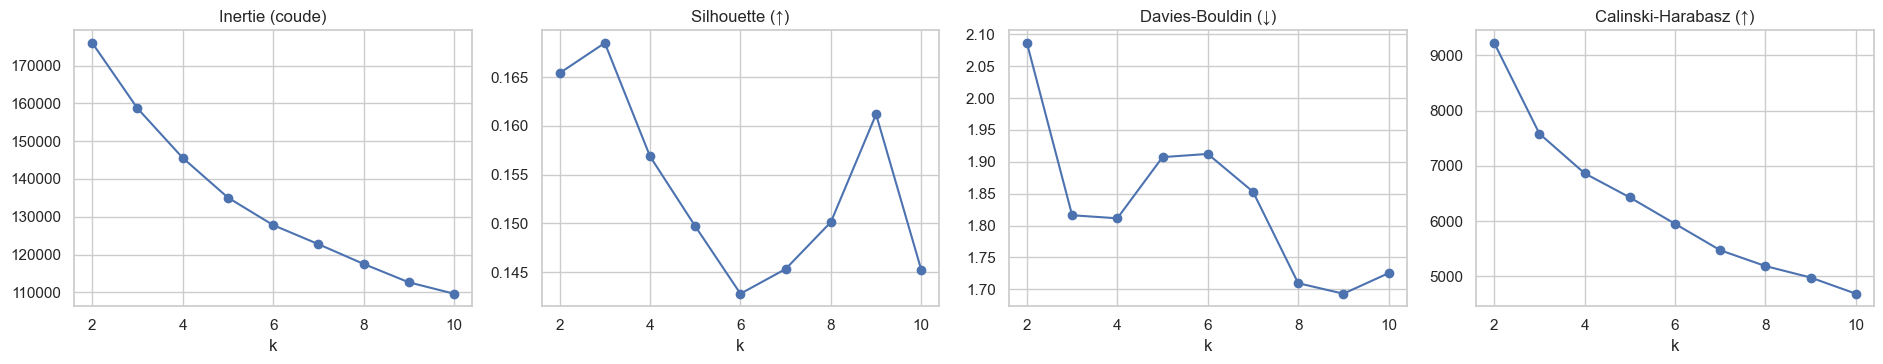

,Inertie,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,175984.744,0.165,2.086,9224.201
3,158673.701,0.169,1.816,7581.211
4,145584.445,0.157,1.811,6863.253
5,135076.767,0.150,1.907,6426.896
6,127802.624,0.143,1.912,5948.621
7,122758.607,0.145,1.853,5470.316
8,117534.802,0.150,1.710,5184.134
9,112667.253,0.161,1.693,4976.092
10,109645.418,0.145,1.725,4683.418


In [11]:
k_range = range(2, 11)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_onehot)
    km_rows.append({"k": k, "Inertie": km.inertia_,
                    "Silhouette": silhouette_score(X_onehot[idx_sil], km.labels_[idx_sil]),
                    "Davies-Bouldin": davies_bouldin_score(X_onehot, km.labels_),
                    "Calinski-Harabasz": calinski_harabasz_score(X_onehot, km.labels_)})
km_metrics = pd.DataFrame(km_rows).set_index("k")

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, col, better in zip(axes, km_metrics.columns, ["coude", "↑", "↓", "↑"]):
    ax.plot(km_metrics.index, km_metrics[col], marker="o")
    ax.set_title(f"{col} ({better})")
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()
km_metrics

**Lecture honnête :**
- La courbe d'inertie décroît **sans coude net**, et la silhouette reste **faible** (≈ 0,13–0,16).
- C'est **normal** sur des données clients réelles : la clientèle forme un **continuum**, pas des « nuages » séparés. Les métriques sont un **guide**, pas un verdict.
- Le choix de *k* est donc aussi **métier** : assez de segments pour différencier les offres, pas trop pour rester **actionnable** (une équipe marketing gère rarement plus de 5–7 segments).

👉 On retient **k = 5** pour la suite (et pour comparer les trois méthodes à nombre de segments égal).

Tailles des segments K-Means : [ 2060 12567 10431  8765 11388]


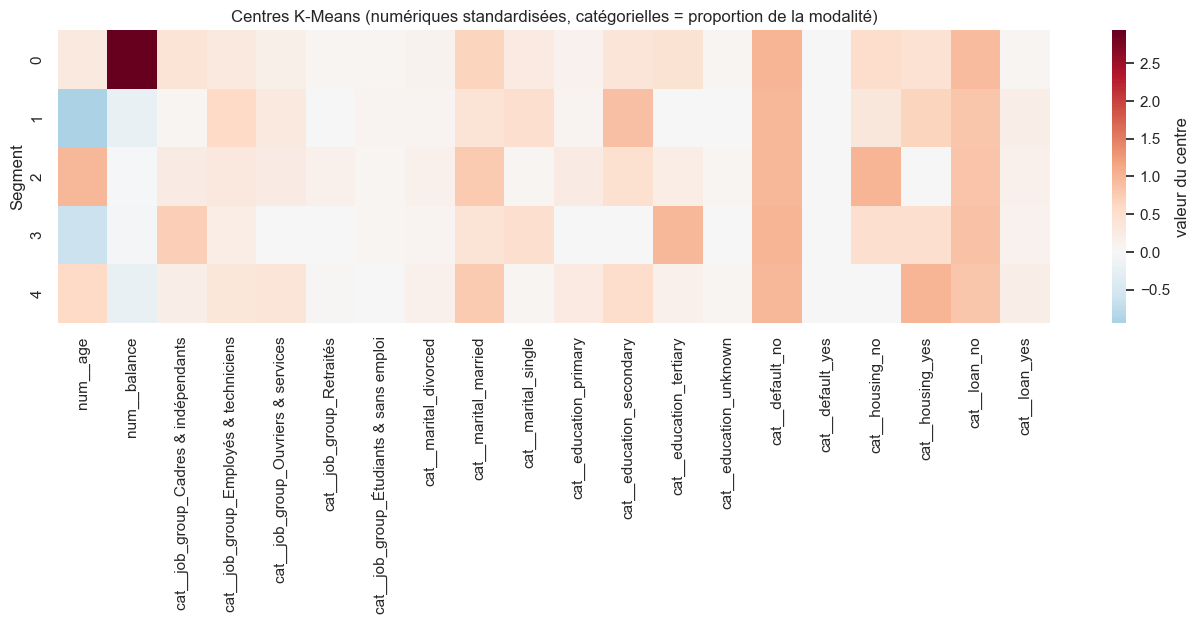

In [12]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_onehot)
df["seg_kmeans"] = kmeans.labels_
print("Tailles des segments K-Means :", np.bincount(kmeans.labels_))

centers = pd.DataFrame(kmeans.cluster_centers_, columns=onehot_names)
plt.figure(figsize=(16, 3.8))
sns.heatmap(centers, cmap="RdBu_r", center=0, annot=False, cbar_kws={"label": "valeur du centre"})
plt.title("Centres K-Means (numériques standardisées, catégorielles = proportion de la modalité)")
plt.ylabel("Segment")
plt.show()

**Lecture :** sur données one-hot, K-Means a tendance à découper selon des variables **binaires** très présentes (ici `housing`, `education = tertiary`) : un segment ressort avec **100 %** de crédits immobiliers, un autre avec **0 %**. Les variables catégorielles encodées en 0/1 « tirent » les centres, et la notion de **moyenne** d'une variable catégorielle a peu de sens… d'où K-Prototypes.

### 5.2 Visualisation en 2D avec l'ACP

L'**ACP** (analyse en composantes principales) projette les 20 dimensions sur les 2 axes qui conservent le plus de variance. C'est une technique de **réduction de dimensionnalité**, l'autre grande famille du non supervisé.

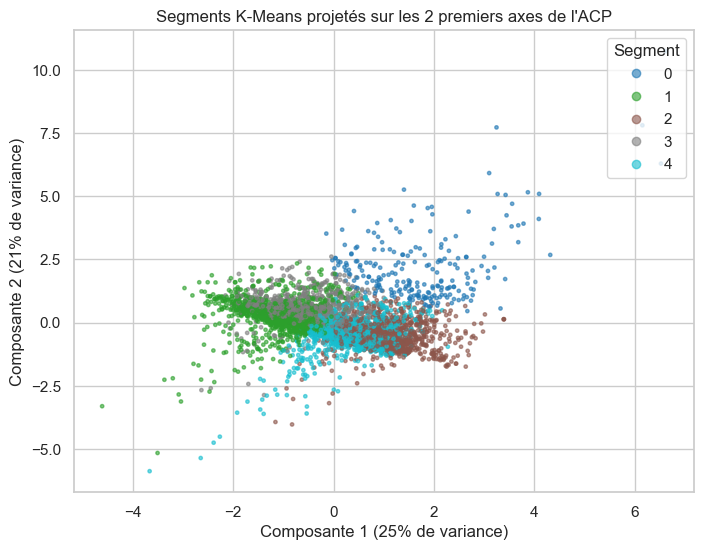

In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_onehot)
coords = pca.transform(X_onehot[idx_sil])
plt.figure(figsize=(8, 6))
sc = plt.scatter(coords[:, 0], coords[:, 1], c=kmeans.labels_[idx_sil], cmap="tab10", s=6, alpha=0.6)
plt.legend(*sc.legend_elements(), title="Segment", loc="upper right")
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]:.0%} de variance)")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]:.0%} de variance)")
plt.title("Segments K-Means projetés sur les 2 premiers axes de l'ACP")
plt.show()

---
## 6. K-Prototypes : le clustering pour données mixtes

**K-Prototypes** (Huang, 1998) combine :
- **K-Means** pour les variables numériques (distance euclidienne, centre = **moyenne**) ;
- **K-Modes** pour les catégorielles (distance de **Hamming** = nombre de modalités différentes, centre = **mode**).

$$d(\text{client}, \text{prototype}) = \underbrace{\sum_{num} (x_j - \mu_j)^2}_{\text{partie numérique}} + \gamma \times \underbrace{\sum_{cat} \mathbb{1}[x_j \neq \text{mode}_j]}_{\text{partie catégorielle}}$$

Le paramètre **γ (gamma)** règle le **poids relatif** des catégorielles. Par défaut, `kmodes` prend γ = 0,5 × écart-type moyen des numériques (= 0,5 ici, puisqu'elles sont standardisées).

Avantage : les prototypes sont **directement lisibles** (« 34 ans, solde 700 €, cadre, célibataire, diplômé du supérieur, pas de crédit immo »).

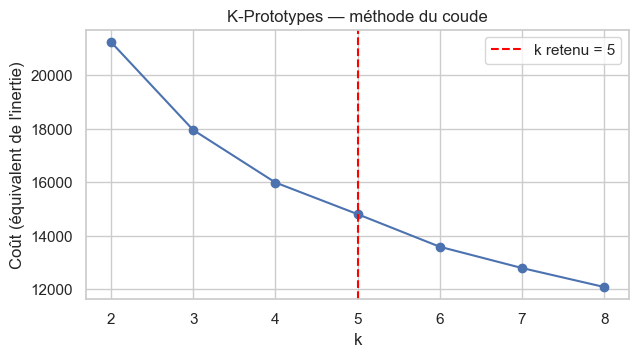

,Coût,Durée (s)
k,,
2,21236.194,3.017
3,17948.502,3.428
4,15985.794,3.280
5,14803.314,2.927
6,13584.896,3.623
7,12790.282,4.333
8,12081.288,3.007


In [14]:
CAT_IDX = list(range(len(SEG_NUM), len(SEG_NUM) + len(SEG_CAT)))

def to_kproto_matrix(data):
    # Numériques transformées + catégorielles brutes, dans une matrice d'objets.
    return np.column_stack([num_pipe.transform(data[SEG_NUM]), data[SEG_CAT].values]).astype(object)

num_pipe.fit(df[SEG_NUM])
X_kp_sample = to_kproto_matrix(df.iloc[idx_kp])
X_kp_all = to_kproto_matrix(df)

kp_rows = []
for k in range(2, 9):
    t0 = time.time()
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=3, random_state=RANDOM_STATE, n_jobs=-1)
    kp.fit(X_kp_sample, categorical=CAT_IDX)
    kp_rows.append({"k": k, "Coût": kp.cost_, "Durée (s)": time.time() - t0})
kp_metrics = pd.DataFrame(kp_rows).set_index("k")

plt.figure(figsize=(7, 3.5))
plt.plot(kp_metrics.index, kp_metrics["Coût"], marker="o")
plt.axvline(K, color="red", ls="--", label=f"k retenu = {K}")
plt.xlabel("k")
plt.ylabel("Coût (équivalent de l'inertie)")
plt.title("K-Prototypes — méthode du coude")
plt.legend()
plt.show()
kp_metrics

### 6.1 Effet du paramètre γ

In [15]:
gamma_rows = []
for gamma in [0.1, 0.5, 1.5, 3.0]:
    kp_g = KPrototypes(n_clusters=K, init="Cao", n_init=3, gamma=gamma, random_state=RANDOM_STATE, n_jobs=-1)
    labels_g = kp_g.fit_predict(X_kp_sample, categorical=CAT_IDX)
    sample = df.iloc[idx_kp].assign(seg=labels_g)
    gamma_rows.append({
        "γ": gamma,
        "Tailles des segments": sorted(np.bincount(labels_g).tolist(), reverse=True),
        "Écart-type de l'âge moyen entre segments": sample.groupby("seg")["age"].mean().std(),
        "Écart-type du % crédit immo entre segments": sample.groupby("seg")["housing"].apply(lambda s: (s == "yes").mean()).std(),
    })
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(gamma_rows).set_index("γ"))

,Tailles des segments,Écart-type de l'âge moyen entre segments,Écart-type du % crédit immo entre segments
γ,,,
0.100,"[3400, 2850, 2780, 692, 278]",8.859,0.149
0.500,"[2890, 2363, 2108, 2014, 625]",9.780,0.214
1.500,"[3625, 1993, 1944, 1838, 600]",9.023,0.232
3.000,"[3424, 2486, 1794, 1424, 872]",8.232,0.348


**Lecture :** quand γ augmente, les **catégorielles** pèsent davantage : les segments se différencient de plus en plus sur le crédit immobilier (l'écart entre segments est multiplié par plus de 2) et la profession, et un peu moins sur l'âge. Avec γ faible, la segmentation est surtout pilotée par l'âge et le solde (avec un micro-segment de soldes extrêmes). **γ est un hyperparamètre métier** : on choisit le dosage qui produit les segments les plus utiles. On garde ici la valeur par défaut.

### 6.2 Modèle final et affectation de tous les clients

In [16]:
kproto = KPrototypes(n_clusters=K, init="Cao", n_init=5, random_state=RANDOM_STATE, n_jobs=-1)
kproto.fit(X_kp_sample, categorical=CAT_IDX)
t0 = time.time()
df["seg_kproto"] = kproto.predict(X_kp_all, categorical=CAT_IDX)
print(f"γ utilisé : {kproto.gamma:.2f}  |  affectation de {len(df):,} clients en {time.time() - t0:.1f} s")
print("Tailles :", np.bincount(df["seg_kproto"]))

prototypes = pd.DataFrame(kproto.cluster_centroids_, columns=SEG_NUM + SEG_CAT)
prototypes[SEG_NUM] = num_pipe.inverse_transform(prototypes[SEG_NUM].astype(float))
prototypes[SEG_NUM] = prototypes[SEG_NUM].round(0)
prototypes.index.name = "Segment"
prototypes

γ utilisé : 0.48  |  affectation de 45,211 clients en 0.3 s
Tailles : [12870  3019 11529 16578  1215]


,age,balance,job_group,marital,education,default,housing,loan
Segment,,,,,,,,
0,53.000,859.000,Employés & techniciens,married,secondary,no,no,no
1,42.000,8484.000,Cadres & indépendants,married,tertiary,no,no,no
2,29.000,593.000,Employés & techniciens,single,secondary,no,yes,no
3,38.000,619.000,Employés & techniciens,married,secondary,no,yes,no
4,40.000,-661.000,Employés & techniciens,married,secondary,no,yes,no


> Les prototypes sont **lisibles directement** : âge et solde « typiques » (re-transformés en unités d'origine) et **modalité la plus fréquente** de chaque variable catégorielle.

---
## 7. Classification ascendante hiérarchique (CAH)

**Principe :** on part de *n* groupes (1 client = 1 groupe) et on **fusionne** à chaque étape les deux groupes les plus proches, jusqu'à n'en avoir plus qu'un. Le résultat est un **dendrogramme**, qu'on « coupe » à la hauteur voulue → pas besoin de fixer *k* à l'avance.

Le **critère d'agrégation** (*linkage*) définit la distance entre deux groupes :

| Linkage | Distance entre groupes | Comportement |
|---|---|---|
| **Ward** | hausse de l'inertie intra-groupe si on fusionne | groupes compacts et équilibrés (euclidien uniquement) |
| **Complet** | distance **maximale** entre leurs membres | groupes compacts |
| **Moyen** | distance **moyenne** entre leurs membres | intermédiaire |
| **Simple** | distance **minimale** | effet de « chaîne », peu utilisé |

### 7.1 Ward sur données one-hot

CAH Ward sur 3000 clients : 0.1 s


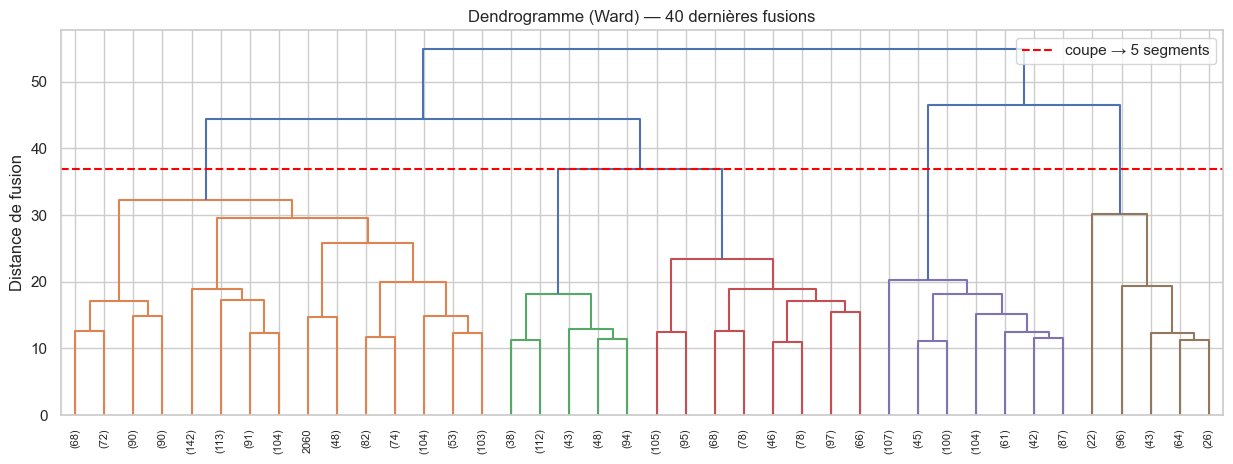

Tailles : [1235  335  633  546  251]


In [17]:
X_cah = X_onehot[idx_cah]
t0 = time.time()
Z_ward = linkage(X_cah, method="ward")
print(f"CAH Ward sur {len(X_cah)} clients : {time.time() - t0:.1f} s")

plt.figure(figsize=(15, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=8,
           color_threshold=Z_ward[-(K - 1), 2])
plt.axhline(Z_ward[-(K - 1), 2], color="red", ls="--", label=f"coupe → {K} segments")
plt.title("Dendrogramme (Ward) — 40 dernières fusions")
plt.ylabel("Distance de fusion")
plt.legend()
plt.show()

labels_ward = fcluster(Z_ward, t=K, criterion="maxclust") - 1
print("Tailles :", np.bincount(labels_ward))

**Lecture du dendrogramme :** la hauteur d'une fusion indique **à quel point les deux groupes fusionnés sont différents**. Un grand saut vertical suggère une bonne coupe : on la place là où les branches sont longues.

### 7.2 Distance de Gower : la distance naturelle des données mixtes

La **distance de Gower** fait la moyenne, variable par variable, de :
- pour une numérique : $|x_i - x_j| / \text{étendue}$ (entre 0 et 1) ;
- pour une catégorielle : 0 si même modalité, 1 sinon.

Elle n'est pas euclidienne → pas de Ward ; on utilise le linkage **moyen** ou **complet**.

Matrice de Gower : (3000, 3000), distances entre 0.00 et 0.90


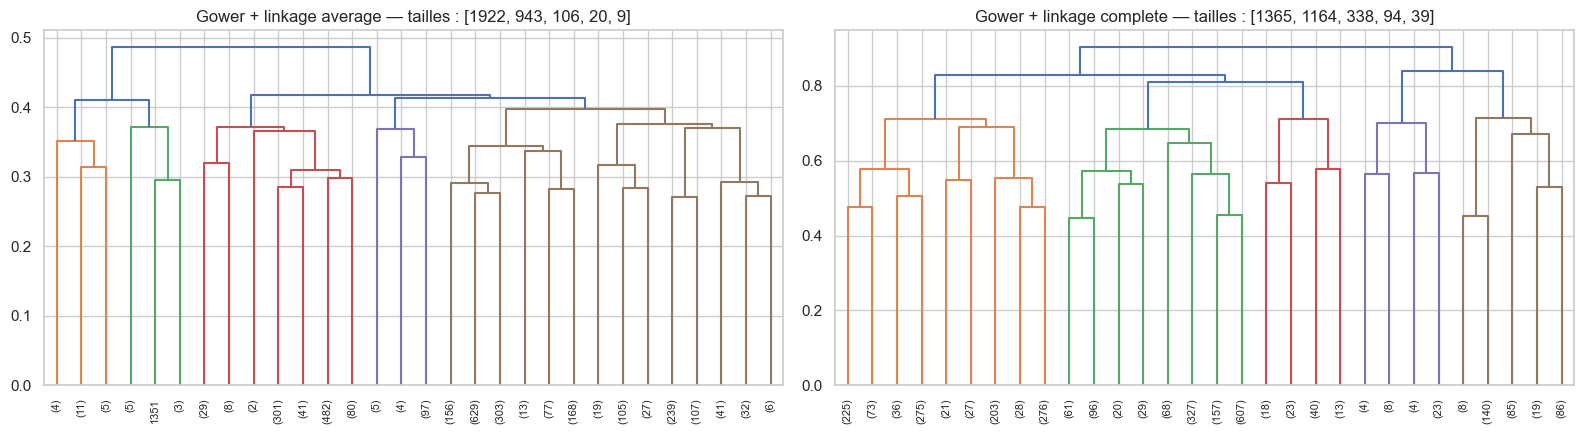

In [18]:
def gower_matrix(num_values, cat_values):
    # Matrice de distances de Gower (n × n) pour des données mixtes.
    n = len(num_values)
    D = np.zeros((n, n), dtype=np.float32)
    for j in range(num_values.shape[1]):
        x = num_values[:, j].astype(float)
        D += np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())
    for j in range(cat_values.shape[1]):
        x = cat_values[:, j]
        D += (x[:, None] != x[None, :])
    return D / (num_values.shape[1] + cat_values.shape[1])

sample_cah = df.iloc[idx_cah]
G = gower_matrix(num_pipe.transform(sample_cah[SEG_NUM]), sample_cah[SEG_CAT].values)
print(f"Matrice de Gower : {G.shape}, distances entre {G.min():.2f} et {G.max():.2f}")

gower_labels = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, method in zip(axes, ["average", "complete"]):
    Z = linkage(squareform(G, checks=False), method=method)
    gower_labels[method] = fcluster(Z, t=K, criterion="maxclust") - 1
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=8,
               color_threshold=Z[-(K - 1), 2])
    ax.set_title(f"Gower + linkage {method} — tailles : {sorted(np.bincount(gower_labels[method]).tolist(), reverse=True)}")
plt.tight_layout()
plt.show()

**Lecture :**
- Le linkage **moyen** produit **un segment géant** et quelques micro-groupes de quelques clients (des profils atypiques) : c'est inutilisable pour le marketing, mais c'est un bon **détecteur d'atypiques**.
- Le linkage **complet** donne des groupes plus équilibrés.
- **À retenir :** le choix de la distance et du linkage change radicalement le résultat. La CAH est excellente pour **explorer** la structure (dendrogramme) sur un échantillon ; pour segmenter **tout** le portefeuille, on préfère K-Means / K-Prototypes, qui savent affecter de nouveaux clients.

---
## 8. Comparaison des approches

Pour comparer équitablement, on évalue toutes les partitions sur le **même échantillon** (3 000 clients) avec la **même distance** (Gower, adaptée aux données mixtes), et on mesure leur **accord** avec l'**Adjusted Rand Index** (ARI : 1 = partitions identiques, 0 = accord dû au hasard).

,Silhouette (Gower),Davies-Bouldin (one-hot),Taille du plus petit segment,Taille du plus grand segment
K-Means (one-hot),0.136,1.898,138.000,817.000
K-Prototypes,0.014,2.100,66.000,1109.000
CAH Ward (one-hot),0.119,2.004,251.000,1235.000
CAH Gower complet,0.203,2.496,39.000,1365.000
CAH Gower moyen,0.164,2.278,9.000,1922.000


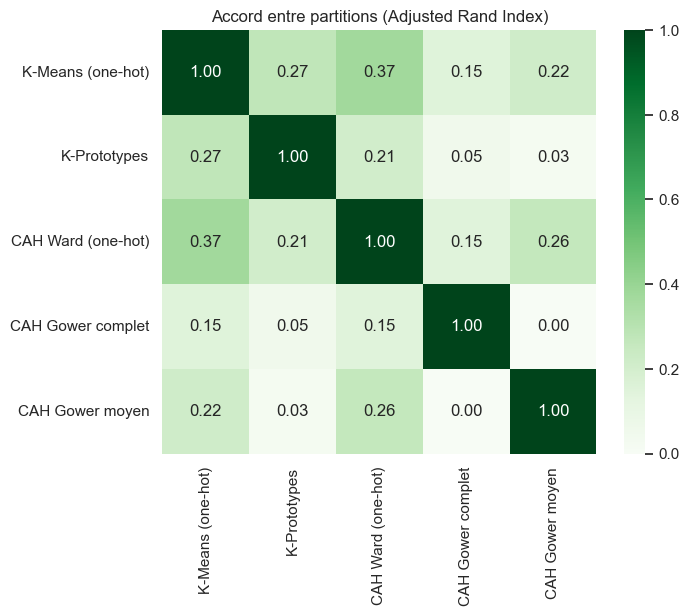

In [19]:
partitions = {
    "K-Means (one-hot)": df["seg_kmeans"].values[idx_cah],
    "K-Prototypes": df["seg_kproto"].values[idx_cah],
    "CAH Ward (one-hot)": labels_ward,
    "CAH Gower complet": gower_labels["complete"],
    "CAH Gower moyen": gower_labels["average"],
}

comp = pd.DataFrame({
    name: {"Silhouette (Gower)": silhouette_score(G, lab, metric="precomputed"),
           "Davies-Bouldin (one-hot)": davies_bouldin_score(X_cah, lab),
           "Taille du plus petit segment": np.bincount(lab).min(),
           "Taille du plus grand segment": np.bincount(lab).max()}
    for name, lab in partitions.items()
}).T
display(comp)

names = list(partitions)
ari = pd.DataFrame([[adjusted_rand_score(partitions[a], partitions[b]) for b in names] for a in names],
                   index=names, columns=names)
plt.figure(figsize=(7, 5.5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1)
plt.title("Accord entre partitions (Adjusted Rand Index)")
plt.show()

**Stabilité :** un bon segment doit être **reproductible**. On relance K-Prototypes sur d'autres échantillons / initialisations et on mesure l'ARI avec la partition de référence.

In [20]:
stab = []
for seed in [1, 2, 3]:
    idx_b = np.random.default_rng(seed).choice(len(df), 10000, replace=False)
    kp_b = KPrototypes(n_clusters=K, init="Cao", n_init=3, random_state=seed, n_jobs=-1)
    kp_b.fit(to_kproto_matrix(df.iloc[idx_b]), categorical=CAT_IDX)
    stab.append(adjusted_rand_score(df["seg_kproto"].values[idx_sil],
                                    kp_b.predict(X_kp_all[idx_sil], categorical=CAT_IDX)))
print("ARI K-Prototypes (autres échantillons vs référence) :", np.round(stab, 2))

ARI K-Prototypes (autres échantillons vs référence) : [0.59 0.47 0.56]


**Synthèse de la comparaison :**

| Méthode | Forces | Limites |
|---|---|---|
| **K-Means** | Rapide, passe à l'échelle, affecte les nouveaux clients | Données numériques uniquement ; one-hot = découpage par variables binaires |
| **K-Prototypes** | **Conçu pour les données mixtes**, prototypes lisibles, affecte les nouveaux clients | Plus lent, choix de γ |
| **CAH** | Pas de *k* a priori, dendrogramme très pédagogique, toute distance possible | O(n²) : échantillon seulement ; pas d'affectation native des nouveaux clients |

**Lecture honnête des résultats :**
- Les méthodes ne trouvent **pas** les mêmes segments (ARI faible à modéré) : il n'y a pas « une » vérité en non supervisé.
- Les **métriques internes** ne désignent pas un vainqueur clair, et elles dépendent de la distance utilisée : la CAH Gower complète a la meilleure silhouette… mais avec un segment de 39 clients et sans possibilité d'affecter de nouveaux clients. K-Prototypes a une silhouette Gower faible car **sa propre distance** (euclidienne + γ × Hamming) n'est pas celle de Gower.
- La **stabilité** de K-Prototypes est **moyenne** (ARI ≈ 0,5–0,6) : les frontières entre segments sont floues, ce qui est typique d'une clientèle formant un continuum. En production, on **fige** le modèle et on contrôle la stabilité à chaque re-segmentation.

👉 Pour la production, on retient **K-Prototypes** pour des raisons **métier** : conçu pour les données mixtes, prototypes lisibles, segments de tailles exploitables, et capable d'affecter les nouveaux clients. **Les métriques guident ; l'utilité métier tranche.**

---
## 9. Profilage métier & personas

Un segment n'a de valeur que s'il est **compris** et **actionnable**. On décrit chaque segment par des indicateurs métier et on lui donne un **nom** (persona). La variable `y` (souscription au dépôt à terme), **non utilisée** pour la segmentation, permet de mesurer l'**appétence** de chaque segment.

In [21]:
def segment_profile(data, seg_col):
    g = data.groupby(seg_col)
    prof = pd.DataFrame({
        "Nb clients": g.size(),
        "% portefeuille": g.size() / len(data),
        "Âge moyen": g["age"].mean(),
        "Solde médian (€)": g["balance"].median(),
        "% solde négatif": g["negative_balance"].mean(),
        "% crédit immo": g["housing"].apply(lambda s: (s == "yes").mean()),
        "% crédit perso": g["loan"].apply(lambda s: (s == "yes").mean()),
        "% défaut": g["default"].apply(lambda s: (s == "yes").mean()),
        "% diplômés sup.": g["education"].apply(lambda s: (s == "tertiary").mean()),
        "% célibataires": g["marital"].apply(lambda s: (s == "single").mean()),
        "% cadres & indép.": g["job_group"].apply(lambda s: (s == "Cadres & indépendants").mean()),
        "% retraités": g["job_group"].apply(lambda s: (s == "Retraités").mean()),
        "Taux souscription": g["y"].apply(lambda s: (s == "yes").mean()),
    })
    prof["Lift souscription"] = prof["Taux souscription"] / (data["y"] == "yes").mean()
    return prof

profile = segment_profile(df, "seg_kproto")
profile.style.format({c: "{:.1%}" for c in profile.columns if c.startswith("%") or c == "Taux souscription"}
                     | {"Nb clients": "{:,.0f}", "Âge moyen": "{:.1f}", "Solde médian (€)": "{:,.0f}",
                        "Lift souscription": "{:.2f}"}).background_gradient(cmap="Blues", axis=0)

,Nb clients,% portefeuille,Âge moyen,Solde médian (€),% solde négatif,% crédit immo,% crédit perso,% défaut,% diplômés sup.,% célibataires,% cadres & indép.,% retraités,Taux souscription,Lift souscription
seg_kproto,,,,,,,,,,,,,,
0,"12,870",28.5%,53.7,518,4.7%,34.5%,16.4%,1.4%,23.7%,7.6%,25.7%,15.6%,12.8%,1.09
1,"3,019",6.7%,43.5,"7,296",0.0%,44.3%,7.3%,0.1%,47.6%,24.6%,45.6%,5.3%,15.2%,1.30
2,"11,529",25.5%,29.5,355,7.5%,58.6%,15.5%,1.8%,34.5%,71.6%,25.7%,0.1%,14.1%,1.21
3,"16,578",36.7%,38.5,382,6.5%,70.0%,16.2%,1.4%,27.5%,15.7%,27.7%,0.4%,9.0%,0.77
4,"1,215",2.7%,40.7,-537,100.0%,81.2%,36.0%,15.5%,23.0%,18.2%,23.3%,2.1%,5.6%,0.48


### Attribution automatique des personas

Les numéros de segments sont **arbitraires** (ils changent d'un entraînement à l'autre). On attribue donc les noms par des **règles métier** appliquées au profil, dans l'ordre :
1. solde médian le plus élevé → **Patrimoniaux**
2. part de soldes négatifs la plus élevée → **Clients fragiles**
3. âge moyen le plus élevé → **Seniors**
4. âge moyen le plus bas → **Jeunes actifs**
5. le segment restant → **Familles propriétaires**

In [22]:
PERSONAS = {
    "Patrimoniaux": {
        "description": "Soldes nettement plus élevés que la moyenne, très peu de crédit personnel, profil plus diplômé et plus souvent cadre.",
        "offres": ["Gestion de patrimoine / conseil", "Assurance-vie et placements", "Carte premium"]},
    "Clients fragiles": {
        "description": "Soldes négatifs (découvert), très forte part de crédits immobiliers et personnels : multi-endettement.",
        "offres": ["Accompagnement budgétaire", "Regroupement de crédits", "Suivi du risque renforcé"]},
    "Seniors": {
        "description": "Clients de plus de 50 ans, majoritairement mariés, peu de crédit immobilier, forte part de retraités.",
        "offres": ["Épargne retraite et dépôt à terme", "Prévoyance / dépendance", "Transmission de patrimoine"]},
    "Jeunes actifs": {
        "description": "Autour de 30 ans, majoritairement célibataires, souvent primo-accédants (crédit immobilier), soldes modestes.",
        "offres": ["Livret et épargne programmée", "Assurance habitation / emprunteur", "Pack jeune actif / crédit auto"]},
    "Familles propriétaires": {
        "description": "Quarantaine, mariés, crédit immobilier en cours pour 7 clients sur 10, soldes modestes ; appétence épargne faible.",
        "offres": ["Prévoyance famille", "Épargne enfants", "Assurance habitation / emprunteur"]},
}

PERSONA_RULES = [("Patrimoniaux", "Solde médian (€)", "max"), ("Clients fragiles", "% solde négatif", "max"),
                 ("Seniors", "Âge moyen", "max"), ("Jeunes actifs", "Âge moyen", "min")]

def assign_personas(prof):
    # Associe un nom de persona à chaque segment à partir de son profil.
    remaining = list(prof.index)
    names = {}
    for persona, col, how in PERSONA_RULES:
        if not remaining:
            break
        sub = prof.loc[remaining, col]
        seg = sub.idxmax() if how == "max" else sub.idxmin()
        names[seg] = persona
        remaining.remove(seg)
    for i, seg in enumerate(remaining):
        names[seg] = "Familles propriétaires" if i == 0 else f"Segment {seg}"
    return names

persona_names = assign_personas(profile)
df["persona"] = df["seg_kproto"].map(persona_names)
profile.index = profile.index.map(persona_names)
profile.index.name = "Persona"
profile[["Nb clients", "% portefeuille", "Âge moyen", "Solde médian (€)", "% crédit immo",
         "% crédit perso", "% solde négatif", "Taux souscription", "Lift souscription"]]

,Nb clients,% portefeuille,Âge moyen,Solde médian (€),% crédit immo,% crédit perso,% solde négatif,Taux souscription,Lift souscription
Persona,,,,,,,,,
Seniors,12870,0.285,53.683,517.500,0.345,0.164,0.047,0.128,1.093
Patrimoniaux,3019,0.067,43.536,7296.000,0.443,0.073,0.000,0.152,1.300
Jeunes actifs,11529,0.255,29.497,355.000,0.586,0.155,0.075,0.141,1.209
Familles propriétaires,16578,0.367,38.537,382.500,0.700,0.162,0.065,0.090,0.767
Clients fragiles,1215,0.027,40.726,-537.000,0.812,0.360,1.000,0.056,0.478


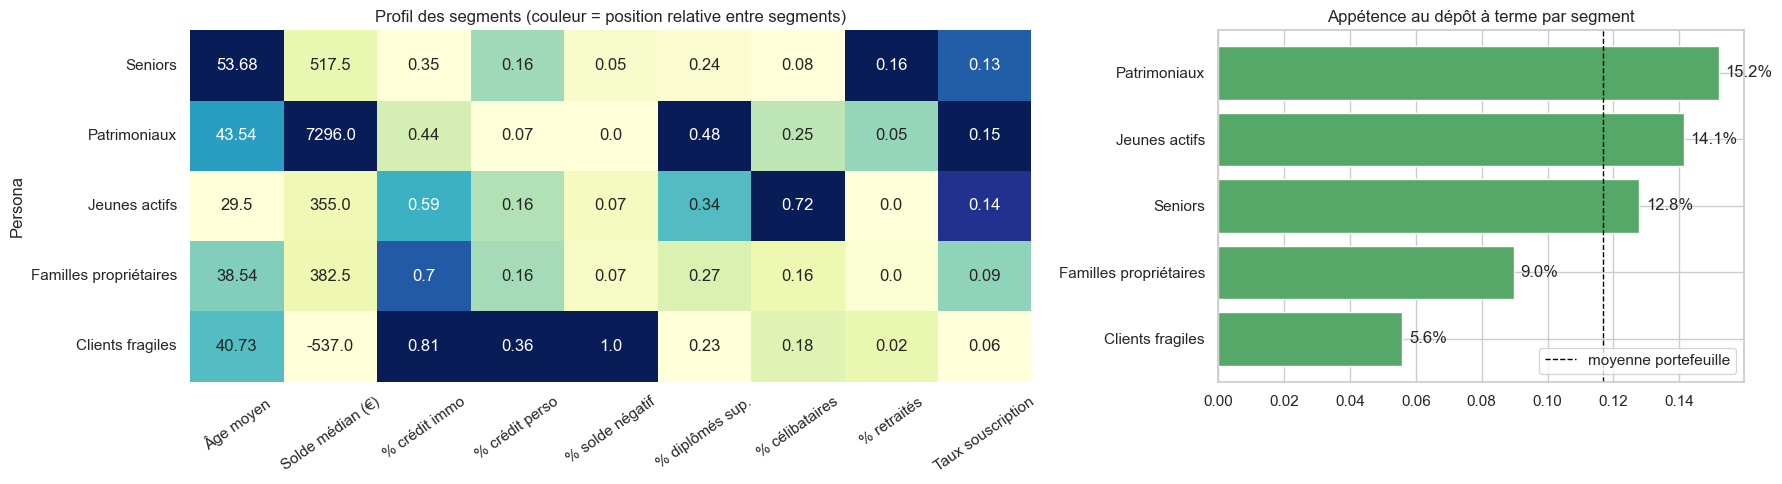

In [23]:
radar_cols = ["Âge moyen", "Solde médian (€)", "% crédit immo", "% crédit perso", "% solde négatif",
              "% diplômés sup.", "% célibataires", "% retraités", "Taux souscription"]
norm = (profile[radar_cols] - profile[radar_cols].min()) / (profile[radar_cols].max() - profile[radar_cols].min())

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(norm, annot=profile[radar_cols].round(2), fmt="", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title("Profil des segments (couleur = position relative entre segments)")
axes[0].tick_params(axis="x", rotation=35)

prof_sorted = profile.sort_values("Taux souscription")
axes[1].barh(prof_sorted.index, prof_sorted["Taux souscription"], color="#55A868")
axes[1].axvline((df["y"] == "yes").mean(), color="black", ls="--", lw=1, label="moyenne portefeuille")
for i, v in enumerate(prof_sorted["Taux souscription"]):
    axes[1].text(v + 0.002, i, f"{v:.1%}", va="center")
axes[1].set_title("Appétence au dépôt à terme par segment")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [24]:
for name, info in PERSONAS.items():
    if name not in profile.index:
        continue
    p = profile.loc[name]
    print(f"■ {name}  —  {p['Nb clients']:,.0f} clients ({p['% portefeuille']:.0%})")
    print(f"   {info['description']}")
    print(f"   Âge moyen {p['Âge moyen']:.0f} ans · solde médian {p['Solde médian (€)']:,.0f} € · "
          f"crédit immo {p['% crédit immo']:.0%} · souscription {p['Taux souscription']:.1%} (lift {p['Lift souscription']:.2f})")
    print(f"   Offres : {', '.join(info['offres'])}\n")

■ Patrimoniaux  —  3,019 clients (7%)
   Soldes nettement plus élevés que la moyenne, très peu de crédit personnel, profil plus diplômé et plus souvent cadre.
   Âge moyen 44 ans · solde médian 7,296 € · crédit immo 44% · souscription 15.2% (lift 1.30)
   Offres : Gestion de patrimoine / conseil, Assurance-vie et placements, Carte premium

■ Clients fragiles  —  1,215 clients (3%)
   Soldes négatifs (découvert), très forte part de crédits immobiliers et personnels : multi-endettement.
   Âge moyen 41 ans · solde médian -537 € · crédit immo 81% · souscription 5.6% (lift 0.48)
   Offres : Accompagnement budgétaire, Regroupement de crédits, Suivi du risque renforcé

■ Seniors  —  12,870 clients (28%)
   Clients de plus de 50 ans, majoritairement mariés, peu de crédit immobilier, forte part de retraités.
   Âge moyen 54 ans · solde médian 518 € · crédit immo 35% · souscription 12.8% (lift 1.09)
   Offres : Épargne retraite et dépôt à terme, Prévoyance / dépendance, Transmission de patrimoi

**Recommandations métier (à challenger avec les équipes marketing et risque) :**
- **Cibler en priorité** les segments au **lift > 1** (Patrimoniaux, Jeunes actifs, Seniors) pour les campagnes de dépôt à terme : on obtient le même nombre de souscriptions avec **moins d'appels**.
- Les **Clients fragiles** ont l'appétence la plus faible et sont tous à découvert : plutôt des actions d'**accompagnement** et une **surveillance du risque** que de la vente d'épargne.
- Les **Familles propriétaires**, segment le plus important, sont peu appétentes à l'épargne : les aborder par la **protection** (prévoyance, assurances) plutôt que par le placement.
- Pour aller plus loin : enrichir la segmentation avec des **variables comportementales** (flux, usage digital, produits détenus, revenus), généralement bien plus discriminantes que le socio-démographique.

---
## 10. Mise en production

### 10.1 Exporter le modèle et affecter un nouveau client

In [25]:
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump({"num_pipe": num_pipe, "kproto": kproto, "persona_names": persona_names,
             "seg_num": SEG_NUM, "seg_cat": SEG_CAT}, "models/segmentation_kproto.joblib")

def assign_client(client: dict) -> dict:
    # Affecte un nouveau client (données brutes) à un segment et renvoie sa persona.
    d = add_features(pd.DataFrame([client]))
    seg = int(kproto.predict(to_kproto_matrix(d), categorical=CAT_IDX)[0])
    persona = persona_names[seg]
    return {"segment": seg, "persona": persona, "offres": PERSONAS.get(persona, {}).get("offres", [])}

new_client = {"age": 28, "balance": 350, "job": "technician", "marital": "single",
              "education": "secondary", "default": "no", "housing": "yes", "loan": "no"}
assign_client(new_client)

{'segment': 2,
 'persona': 'Jeunes actifs',
 'offres': ['Livret et épargne programmée',
  'Assurance habitation / emprunteur',
  'Pack jeune actif / crédit auto']}

### 10.2 Cycle de vie d'une segmentation

- **Affectation** quotidienne / mensuelle des nouveaux clients avec le modèle exporté (`predict`).
- **Suivi** : la répartition des clients entre segments et les distributions des variables sont comparées à la référence (PSI).
- **Re-segmentation** périodique (ex. annuelle) ou déclenchée par une dérive : les segments doivent rester **stables** pour que les équipes métier puissent s'en servir.

Simulation : un lot de nouveaux clients issus d'une campagne digitale (plus **jeunes**, plus souvent **célibataires**).

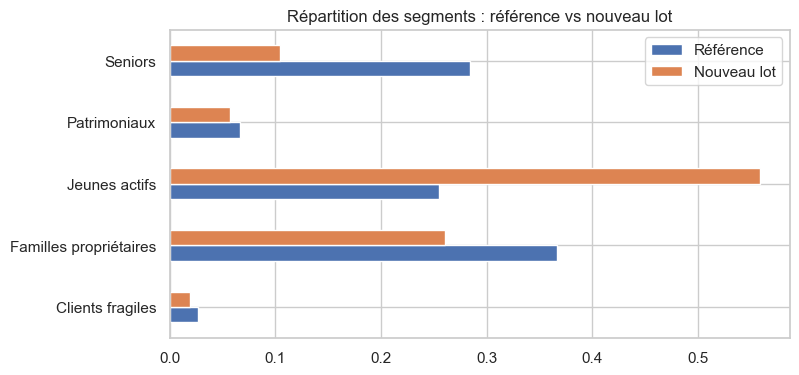

PSI de la répartition des segments : 0.459  (< 0,10 stable · 0,10–0,25 modéré · > 0,25 significatif)


In [26]:
def psi_categorical(reference, current):
    ref = reference.value_counts(normalize=True)
    cur = current.value_counts(normalize=True).reindex(ref.index).fillna(0)
    ref, cur = ref.clip(lower=1e-4), cur.clip(lower=1e-4)
    return float(((cur - ref) * np.log(cur / ref)).sum())

young = df[(df["age"] < 35)].sample(3000, random_state=RANDOM_STATE)
others = df[(df["age"] >= 35)].sample(1000, random_state=RANDOM_STATE)
batch = pd.concat([young, others])[NUM_COLS + CAT_COLS]
batch_seg = pd.Series(kproto.predict(to_kproto_matrix(add_features(batch)), categorical=CAT_IDX)).map(persona_names)

drift = pd.DataFrame({"Référence": df["persona"].value_counts(normalize=True),
                      "Nouveau lot": batch_seg.value_counts(normalize=True)}).fillna(0)
ax = drift.plot.barh(figsize=(8, 4), color=["#4C72B0", "#DD8452"])
ax.set_title("Répartition des segments : référence vs nouveau lot")
plt.show()
print(f"PSI de la répartition des segments : {psi_categorical(df['persona'], batch_seg):.3f}  "
      "(< 0,10 stable · 0,10–0,25 modéré · > 0,25 significatif)")

> La population entrante est très différente (beaucoup plus de **Jeunes actifs**) : le PSI le signale. Ce n'est pas forcément un problème du **modèle**, mais c'est une **information métier** (le mix client change), et si la dérive persiste, une **re-segmentation** peut être nécessaire.

---
## Synthèse

| Étape | Ce qu'il faut retenir |
|---|---|
| Cadrage | Pas de cible : la valeur d'un segment se juge à son **utilité métier** |
| EDA | Asymétries (solde), modalités rares, liens entre variables (V de Cramér) |
| Preprocessing | **Standardiser** (distances !), transformer les variables asymétriques, encoder selon l'algorithme |
| K-Means | Rapide, mais numérique uniquement ; choix de *k* = métriques + métier |
| K-Prototypes | Le bon outil pour les **données mixtes** ; γ dose numérique vs catégoriel |
| CAH | Dendrogramme pour **explorer** ; le choix distance/linkage change tout |
| Évaluation | Silhouette, Davies-Bouldin, Calinski-Harabasz, **stabilité** (ARI) — et surtout l'interprétabilité |
| Profilage | Indicateurs métier, **personas**, offres, appétence (lift) |
| Production | Affectation des nouveaux clients, suivi de la répartition (PSI), re-segmentation périodique |

👉 **Suite :** lancer l'application `apps/segmentation` (API FastAPI + interface Streamlit avec dashboard des segments).